# Lab 3-06（Lab 3）：評估 RAG——基線 vs 最佳組合，拿數字說話

**目標**：把前幾本的零件組成兩條完整管線——「基線」與「最佳組合」——在同一份 38 題題庫上，同時評估檢索與回答。

**你會學到**
- 檢索指標：Hit@k、MRR，以及為什麼要畫 Hit@k 曲線
- 生成指標：規則版（關鍵事實比對）與 LLM 評審，以及小模型當評審有多不可靠
- 錯誤歸因：答錯時，是沒找到（檢索的錯）還是找到了卻答錯（生成的錯）

**前置**：Lab 3-02～3-05。全部跑完約需 5～10 分鐘（76 次回答＋76 次評審，用 4 條執行緒並行送出）。原理見 `00_concepts.md` 第 6 節。

**對應投影片**：「Lab 3 架構」「Lab 3 切分與入庫」「Lab 3 檢索到組裝」「RAG 常見踩坑」「面試：RAG 檢索」

![RAG 評估](images/eval_loop.jpg)

*圖：同一份題庫跑過 RAG 管線，分兩條線評估：上面看「排名文件」算 Hit@k、MRR（檢索好不好），下面讓 LLM 評審看「回答」算答對率（生成好不好）。右邊是我們最後要畫的前後對比。*

## Step 1：題庫長什麼樣

38 題，每題有問題、標準答案、應命中的文件。23 題靠關鍵字（錯誤碼、指令、設定鍵），15 題靠語意（口語描述）。
題庫是評估的地基：題目要像真實使用者會問的，標準答案要有人確認過。

In [1]:
from collections import Counter

from rag_utils import load_docs, load_qa

docs = load_docs()
qa = load_qa()
print(Counter(q["type"] for q in qa))
for q in qa[:3] + qa[15:17]:
    print(f"{q['id']} [{q['type']}] {q['question']}\n     答：{q['answer']}\n     文件：{q['doc_ids']}")

Counter({'keyword': 23, 'semantic': 15})
q01 [keyword] TP-4021 是什麼錯誤？可以重試嗎？
     答：冪等鍵衝突：同一個 Idempotency-Key 但請求內容不同，是呼叫端程式錯誤，不可重試。
     文件：['svc-tidepay']
q02 [keyword] TP-4012 每小時多少筆以上才需要處理？
     答：每小時超過 300 筆，或比上週同時段高 5 倍以上。
     文件：['rb-tp-4012-3ds-timeout']
q03 [keyword] 出現 TP-5003 時要切換到哪一家收單行？指令是什麼？
     答：切換到備援收單行 acq-b，指令 hfctl tidepay failover --to acq-b，需要第二位值班人員核准。
     文件：['rb-tp-5003-acquirer-failover', 'faq-hfctl']
q16 [semantic] 使用者付款時一直被扣兩次錢，以前發生過嗎？原因是什麼？
     答：發生過（INC-2026-0314），冪等鍵保存時間被改成 1 小時，App 背景補送時鍵已過期，被當成新付款。
     文件：['pm-2026-0314-double-charge']
q17 [semantic] 大家突然一直被登出、登入後又跳回登入頁，可能是什麼原因？
     答：多半是金鑰剛輪換、下游 JWKS 快取還是舊的（AUTH-1109），執行 hfctl auth jwks refresh --all。
     文件：['rb-auth-1109-jwks', 'pm-2026-0607-auth-outage']


## Step 2：兩條管線

| | 基線 | 最佳組合 |
|---|---|---|
| 切塊 | 固定 128 token | 依標題＋補標題 |
| 檢索 | 向量 | BM25＋向量，RRF |
| 過濾 | 無 | 排除已封存文件 |
| 重排 | 無 | cross-encoder，20 選 3 |

兩條都取前 3 塊組 prompt。

In [2]:
from collections import Counter as _Counter

from llama_index.core import Document
from llama_index.core.node_parser import TokenTextSplitter
from sentence_transformers import CrossEncoder

from rag_utils import BM25Index, Chunk, build_collection, chunk_docs, rrf, vector_search

# 基線：固定長度切塊、只用向量
nodes = TokenTextSplitter(chunk_size=128, chunk_overlap=16).get_nodes_from_documents(
    [Document(text=d.text, id_=d.doc_id) for d in docs])
seen = _Counter()
base_chunks = []
for n in nodes:
    base_chunks.append(Chunk(f"{n.ref_doc_id}#{seen[n.ref_doc_id]}", n.ref_doc_id, n.text))
    seen[n.ref_doc_id] += 1
base_col = build_collection(base_chunks, "eval_base")
base_text = {c.chunk_id: c.text for c in base_chunks}

# 最佳組合：依標題＋補標題、混合檢索、過濾、重排
best_chunks = chunk_docs(docs)
best_col = build_collection(best_chunks, "eval_best")
best_text = {c.chunk_id: c.text for c in best_chunks}
bm25 = BM25Index(best_chunks)
allowed = {c.chunk_id for c in best_chunks if c.meta["status"] == "current"}
reranker = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")
print("基線", len(base_chunks), "塊；最佳組合", len(best_chunks), "塊")

基線 153 塊；最佳組合 113 塊


In [3]:
import numpy as np

CURRENT = {"status": "current"}


def retrieve_base(q: str) -> list[str]:
    return vector_search(base_col, q, 10)


def retrieve_best(q: str) -> list[str]:
    candidates = rrf([bm25.search(q, 20, allowed), vector_search(best_col, q, 20, CURRENT)])[:20]
    scores = reranker.predict([(q, best_text[c]) for c in candidates])
    return [candidates[i] for i in np.argsort(-scores)]


pipelines = {"基線": (retrieve_base, base_text), "最佳組合": (retrieve_best, best_text)}
print(retrieve_best("TP-4021 可以重試嗎？")[:3])

['svc-tidepay#3', 'rb-tp-4012-3ds-timeout#3', 'faq-local-dev#2']


## Step 3：檢索指標

只需要每題的「文件排名」與標準文件，各三行：
- **Hit@k**：前 k 名有沒有命中。
- **MRR**：第一個命中的名次取倒數再平均。第 1 名命中得 1，第 2 名得 0.5，沒命中得 0。

有標準文件 id 時，這兩個指標最直接；Ragas 等套件的 context recall／precision 是在**沒有**標註時用 LLM 去猜，留到模組 8。

In [4]:
from rag_utils import dedup_docs


def hit_at_k(ranked: list[str], gold: list[str], k: int) -> float:
    return float(any(d in gold for d in ranked[:k]))


def reciprocal_rank(ranked: list[str], gold: list[str]) -> float:
    return next((1 / r for r, d in enumerate(ranked, start=1) if d in gold), 0.0)


rankings = {name: {q["id"]: dedup_docs(fn(q["question"])) for q in qa} for name, (fn, _) in pipelines.items()}
for name, ranks in rankings.items():
    h = {k: np.mean([hit_at_k(ranks[q["id"]], q["doc_ids"], k) for q in qa]) for k in (1, 3, 5)}
    mrr = np.mean([reciprocal_rank(ranks[q["id"]], q["doc_ids"]) for q in qa])
    print(f"{name:<6} Hit@1 {h[1]:.2f}  Hit@3 {h[3]:.2f}  Hit@5 {h[5]:.2f}  MRR {mrr:.2f}")

基線     Hit@1 0.89  Hit@3 1.00  Hit@5 1.00  MRR 0.94
最佳組合   Hit@1 0.97  Hit@3 1.00  Hit@5 1.00  MRR 0.99


## Step 4：Hit@k 曲線

只看單一個 k 會漏掉資訊。畫出 k＝1～8，看曲線多快爬到頂：爬得快代表正確文件排得前面，prompt 裡只放少數幾塊就夠。

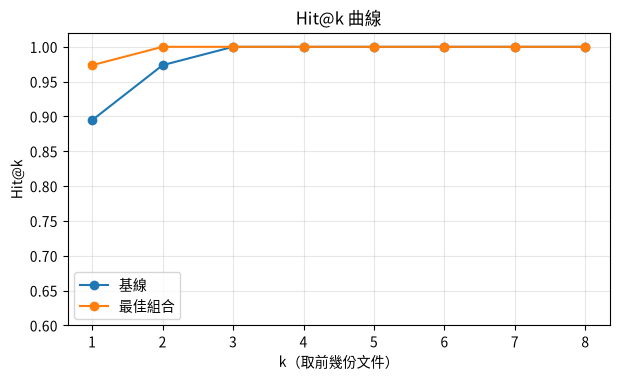

In [5]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

ks = range(1, 9)
plt.figure(figsize=(7, 3.8))
for name, ranks in rankings.items():
    plt.plot(ks, [np.mean([hit_at_k(ranks[q["id"]], q["doc_ids"], k) for q in qa]) for k in ks], marker="o", label=name)
plt.xlabel("k（取前幾份文件）")
plt.ylabel("Hit@k")
plt.ylim(0.6, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.title("Hit@k 曲線")
plt.show()

## Step 5：產生回答

跟 Lab 3-02 一樣的 prompt，取前 3 塊。兩條管線各答 38 題，共 76 次 LLM 呼叫。
一題一題等太慢，用 `ThreadPoolExecutor` 同時送 4 個請求（Ollama 會並行處理或排隊），並用 `max_tokens` 限制回答長度。

In [6]:
from concurrent.futures import ThreadPoolExecutor

from rag_utils import ask

PROMPT = """你是海風科技的內部技術助理。只能根據下面的「參考資料」回答問題。
如果參考資料裡沒有答案，就回答「資料中沒有這個資訊」，不要猜。回答要簡短。

參考資料：
{context}

問題：{question}"""


def answer(q: str, name: str) -> str:
    fn, text = pipelines[name]
    context = "\n\n".join(text[c] for c in fn(q)[:3])
    return ask([{"role": "user", "content": PROMPT.format(context=context, question=q)}], max_tokens=200).strip()


def run_parallel(fn, items, workers: int = 4) -> list:
    with ThreadPoolExecutor(max_workers=workers) as pool:
        return list(pool.map(fn, items))


answers = {}
answers["基線"] = dict(zip([q["id"] for q in qa], run_parallel(lambda q: answer(q["question"], "基線"), qa)))
print("基線答完", len(answers["基線"]), "題")

基線答完 38 題


In [7]:
answers["最佳組合"] = dict(zip([q["id"] for q in qa], run_parallel(lambda q: answer(q["question"], "最佳組合"), qa)))
for q in qa[:2]:
    print(q["question"])
    for name in pipelines:
        print(f"  {name}：{answers[name][q['id']][:100]}")

TP-4021 是什麼錯誤？可以重試嗎？
  基線：TP-4021 的錯誤是「冪等鍵衝突：同一鍵但請求內容不同」。資料中沒有提到可以重試。
  最佳組合：TP-4021 是冪等鍵衝突，是我們自己的程式錯誤，不可重試，要查呼叫端。
TP-4012 每小時多少筆以上才需要處理？
  基線：資料中沒有這個資訊
  最佳組合：TP-4012 每小時超過 300 筆，或比上週同時段高 5 倍以上，才需要處理。


## Step 6：規則版——關鍵事實有沒有出現

回答是自由文字，不能整句比對。但標準答案裡的**代碼、數字、指令**（`acq-b`、`300`、`14:00`）是硬事實：回答裡沒有出現，多半就是沒答到。
規則：從標準答案抽出英數 token（沒有英數時改用 jieba 切出的中文詞），算回答包含了幾成；達到一半就算答對。回答「資料中沒有」直接算錯。

這個規則很粗糙（例如「不可重試」這種結論它看不到），但它**確定、免費、可重現**，適合當底線。

In [8]:
import re

import jieba

FACT_RE = re.compile(r"[A-Za-z0-9][A-Za-z0-9_.:\-/%]*")
STOP = {"可以", "不可", "以上", "需要", "處理", "就是", "如果", "因為", "所以", "沒有", "一個", "什麼"}


def normalize(text: str) -> str:
    return re.sub(r"[\s,`，]", "", text).lower()


def key_facts(reference: str) -> list[str]:
    ref = reference.replace(",", "")
    facts = [t for t in FACT_RE.findall(ref) if any(ch.isdigit() for ch in t) or len(t) >= 3]
    if facts:
        return [normalize(f) for f in facts]
    return [w for w in jieba.lcut(ref) if len(w) >= 2 and w not in STOP]


def fact_recall(reference: str, ans: str) -> float:
    if "資料中沒有" in ans:
        return 0.0
    facts, a = key_facts(reference), normalize(ans)
    return sum(f in a for f in facts) / len(facts) if facts else 0.0


for q in qa[:4]:
    r = fact_recall(q["answer"], answers["最佳組合"][q["id"]])
    print(f"{q['id']} 關鍵事實 {key_facts(q['answer'])} → 命中 {r:.0%}")

rule_ok = {name: {q["id"]: fact_recall(q["answer"], answers[name][q["id"]]) >= 0.5 for q in qa} for name in pipelines}
print({name: round(float(np.mean(list(v.values()))), 2) for name, v in rule_ok.items()})

q01 關鍵事實 ['idempotency-key'] → 命中 0%
q02 關鍵事實 ['300', '5'] → 命中 100%
q03 關鍵事實 ['acq-b', 'hfctl', 'tidepay', 'failover', 'acq-b'] → 命中 100%
q04 關鍵事實 ['auth-1107', 'access', 'token', 'refresh', 'token', 'auth-1109', 'kid', 'jwks'] → 命中 100%
{'基線': 0.63, '最佳組合': 0.74}


## Step 7：LLM 當評審

規則看不懂語意，所以再請 LLM 判斷：核心事實一致就算對。只要它回一個字，越短越不容易跑題。

In [9]:
JUDGE = """判斷「學生回答」有沒有答對「問題」。以「參考答案」為準：學生回答的核心事實（數字、代碼、指令、可不可以）和參考答案一致就算答對，少講次要細節也算對；講錯核心事實、或說資料中沒有，就算答錯。
只回一個字：對 或 錯。

問題：{question}
參考答案：{reference}
學生回答：{answer}"""


def judge(q: dict, ans: str) -> bool:
    out = ask([{"role": "user", "content": JUDGE.format(question=q["question"], reference=q["answer"], answer=ans)}],
              max_tokens=5)
    return out.strip().startswith("對")


llm_ok = {name: dict(zip([q["id"] for q in qa], run_parallel(lambda q: judge(q, answers[name][q["id"]]), qa)))
          for name in pipelines}
print({name: round(float(np.mean(list(v.values()))), 2) for name, v in llm_ok.items()})

{'基線': 0.84, '最佳組合': 0.76}


## Step 8：兩個評審意見一致嗎？

把規則與 LLM 評審的判斷放在一起。一致率不高時，**不要直接相信任何一方**，把不一致的題目拿出來自己看。

In [10]:
agree = np.mean([rule_ok[n][q["id"]] == llm_ok[n][q["id"]] for n in pipelines for q in qa])
print(f"規則與 LLM 評審一致率：{agree:.0%}")
shown = 0
for q in qa:
    r, l = rule_ok["最佳組合"][q["id"]], llm_ok["最佳組合"][q["id"]]
    if r != l and shown < 6:
        shown += 1
        print(f"\n{q['id']} {q['question']}")
        print(f"   標準：{q['answer']}")
        print(f"   回答：{answers['最佳組合'][q['id']][:100]}")
        print(f"   規則：{'對' if r else '錯'}｜LLM 評審：{'對' if l else '錯'}")

規則與 LLM 評審一致率：72%

q01 TP-4021 是什麼錯誤？可以重試嗎？
   標準：冪等鍵衝突：同一個 Idempotency-Key 但請求內容不同，是呼叫端程式錯誤，不可重試。
   回答：TP-4021 是冪等鍵衝突，是我們自己的程式錯誤，不可重試，要查呼叫端。
   規則：錯｜LLM 評審：對

q04 AUTH-1107 和 AUTH-1109 差在哪？
   標準：AUTH-1107 是 access token 過期，屬正常流程，用 refresh token 換新；AUTH-1109 是簽章驗證失敗、找不到 kid，通常是金鑰輪換後 JWKS 快取沒更新。
   回答：AUTH-1107 和 AUTH-1109 的主要區別在於錯誤的原因和處理方式：

- AUTH-1107 的原因是 access token 已過期，處理方式是客戶端使用 refresh token
   規則：對｜LLM 評審：錯

q07 ORD-2201 是什麼意思？
   標準：預留庫存逾時，harbor-stock 沒在 3 秒內回應。
   回答：ORD-2201 預留庫存逾時（harbor-stock 沒在 3 秒內回應）。
   規則：對｜LLM 評審：錯

q08 BW-503 出現時應該先查哪裡？
   標準：BW-503 是熔斷，先從日誌的 upstream= 欄位找出是哪個上游服務，去查那個服務；不要調高錯誤率門檻。
   回答：BW-503 出現時應該先查 breakwater 日誌，找出是哪個服務的錯誤率超過 50%。
   規則：對｜LLM 評審：錯

q10 INC-2026-0607 停機多久？根本原因是什麼？
   標準：約 47 分鐘；金鑰輪換後 breakwater 的 JWKS 快取設成 6 小時，不認得新金鑰。
   回答：INC-2026-0607 停機約 47 分鐘。

根本原因是 breakwater 將快取時間從 10 分鐘調成 6 小時，但仍然使用舊的公鑰清單，導致無法認證新簽發的權杖。
   規則：對｜LLM 評審：錯

q16 使用者付款時一直被扣兩次錢，以前發生過嗎？原因是什麼？
   標準：發生過（INC-2026-0314），冪等鍵保存時間被改成 1 小時，App 背景補送時鍵已過期，被當成新付款。
  

自己判斷上面幾題，會發現兩邊各有誤判：規則看不到「不可重試」「發生過」這種結論，把答對的判錯；3B 評審則常把幾乎逐字照抄文件的正確答案判錯，兩條管線的 LLM 答對率甚至跟檢索指標反方向走。這是小模型當評審的真實狀況：
正式專案要用更強的模型當評審、固定評審 prompt、並定期抽樣人工複查（模組 8 專門講）。本 notebook 接下來用**規則版**做錯誤歸因，LLM 評審只當參考。

## Step 9：錯誤歸因——是誰的錯？

對每一題同時看兩件事：前 3 名有沒有命中標準文件（檢索）、規則版說答對沒（生成）。

| | 答對 | 答錯 |
|---|---|---|
| **檢索命中** | 正常 | 生成的錯：資料有，模型沒用好 |
| **檢索沒中** | 運氣或模型本來就知道 | 檢索的錯：先修檢索 |

In [11]:
import pandas as pd

rows = []
for name in pipelines:
    for q in qa:
        hit = hit_at_k(rankings[name][q["id"]], q["doc_ids"], 3) == 1.0
        ok = rule_ok[name][q["id"]]
        kind = ("正常" if ok else "生成的錯") if hit else ("沒命中但答對" if ok else "檢索的錯")
        rows.append({"管線": name, "id": q["id"], "類別": kind})
diag = pd.DataFrame(rows)
print(pd.crosstab(diag["管線"], diag["類別"]))

類別    正常  生成的錯
管線            
基線    24    14
最佳組合  28    10


In [12]:
print("最佳組合仍答錯的題目：")
for q in qa:
    kind = diag[(diag["管線"] == "最佳組合") & (diag["id"] == q["id"])]["類別"].item()
    if kind != "正常":
        print(f"  {q['id']} [{kind}] {q['question']}\n      回答：{answers['最佳組合'][q['id']][:80]}")

最佳組合仍答錯的題目：
  q01 [生成的錯] TP-4021 是什麼錯誤？可以重試嗎？
      回答：TP-4021 是冪等鍵衝突，是我們自己的程式錯誤，不可重試，要查呼叫端。
  q16 [生成的錯] 使用者付款時一直被扣兩次錢，以前發生過嗎？原因是什麼？
      回答：是的，使用者付款時一直被扣兩次錢的事故以前發生過。原因是因為冪等鍵保存時間設置為 1 小時，比客戶端可能重送的時間範圍（最長 24 小時）還短。
  q17 [生成的錯] 大家突然一直被登出、登入後又跳回登入頁，可能是什麼原因？
      回答：可能是因為簽章金鑰輪換導致的簽章驗證失敗，使用者在使用新簽發的權杖時無法正確驗證，導致被登出，再重新登入時同樣失敗。
  q18 [生成的錯] 出貨通知寄得很慢，要怎麼加速消化積壓的訊息？
      回答：出貨通知寄得很慢，要加速消化積壓的訊息的方法包括：

1. 增加 gull-notify 消費者的數量，充分利用所有分區的處理能力。
2. 优化与简讯商的交互，
  q21 [生成的錯] 新版上線後發現有問題，要怎麼退回舊版？需要誰同意？
      回答：資料中沒有這個資訊
  q27 [生成的錯] 搜尋某些商品突然找不到，以前有類似事故嗎？
      回答：資料中沒有這個資訊。
  q28 [生成的錯] 會員下單後還沒揀貨，可以自己取消嗎？
      回答：可以，會員在 PICKING 狀態之前可以自行取消訂單，系統會自動退款。
  q29 [生成的錯] 限量商品開賣時大家搶不到，可以怎麼緩解？
      回答：可以通過以下方式緩解限量商品開賣時大家搶不到的問題：

1. **預留機制**：下單時預留，預留有效 20 分鐘；付款成功轉成正式扣庫存，逾時或取消則自動釋放。
  q31 [生成的錯] BW-504 是什麼？
      回答：BW-504 上游逾時，超過 `upstream_timeout_ms`。
  q37 [生成的錯] 4000 0000 0000 0010 這張測試卡會發生什麼事？
      回答：4000 0000 0000 0010 这张卡会触发 TP-4040 拒绝。


## Step 10：前後對比圖

               基線  最佳組合
Hit@1        0.89  0.97
Hit@3        1.00  1.00
MRR          0.94  0.99
答對率（規則）      0.63  0.74
答對率（LLM 評審）  0.84  0.76


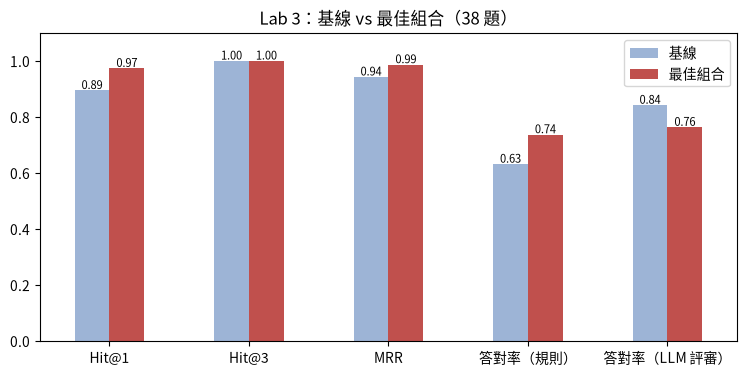

In [13]:
metrics = {}
for name, ranks in rankings.items():
    metrics[name] = {
        "Hit@1": np.mean([hit_at_k(ranks[q["id"]], q["doc_ids"], 1) for q in qa]),
        "Hit@3": np.mean([hit_at_k(ranks[q["id"]], q["doc_ids"], 3) for q in qa]),
        "MRR": np.mean([reciprocal_rank(ranks[q["id"]], q["doc_ids"]) for q in qa]),
        "答對率（規則）": np.mean(list(rule_ok[name].values())),
        "答對率（LLM 評審）": np.mean(list(llm_ok[name].values())),
    }
table = pd.DataFrame(metrics)
print(table.round(2))

ax = table.plot.bar(rot=0, figsize=(9, 4), color=["#9db4d6", "#c0504d"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_title(f"Lab 3：基線 vs 最佳組合（{len(qa)} 題）")
plt.show()

讀圖時注意兩件事：
- 檢索指標是確定的（同樣輸入、同樣結果）；兩種答對率都有雜訊（規則太粗、LLM 評審不穩），相差一兩題不要過度解讀。
- 檢索變好不保證回答變好：3B 模型會在資料齊全時仍然答錯（Step 9 的「生成的錯」）。這時候換更大的模型、改 prompt，比再調檢索有效。

## 試試看

1. 把組 prompt 的塊數從 3 改成 1 和 6，重跑 Step 5～9。塊數多，答對率一定比較高嗎？
2. 自己再寫 5 題（記得標 `doc_ids`），特別挑「最佳組合」可能答錯的類型，加進題庫重跑。
3. 把評審換成更嚴格的規則（例如要求回答必須引用來源），看答對率變化，並抽 5 題人工檢查評審是否合理。

## 小結

- 有標註的題庫，檢索用 Hit@k、MRR 就能精確量；生成用「規則＋LLM 評審」兩種意見互相檢查，因為兩者都會錯。
- 每一題都歸因到「檢索的錯」或「生成的錯」，才知道下一步該修哪一段。
- 下一本 Lab 3-07 用 LlamaIndex 把整條管線重組一次，用同一份題庫對照我們的版本。